### The Problem

*Already, as of 2010, a quarter of Americans (24 percent) had posted product reviews or comments online, and
78 percent of internet users had gone online for product research. But those are ancient stats. Numbers are
higher now. More recently, BrightLocal found in 2016 that 91 percent of consumers regularly or occasionally
read online reviews, with 47 percent taking sentiment of local-business reviews — the tonality of a review’s
text — into account in purchasing decisions. Breaking out the figures, 74 percent of consumers say that positive
reviews make them trust a local business more, and 60 percent say that negative reviews make them not want to
use a business, according to BrightLocal.*

Customer reviews contain several forms of salient information. First there's the star rating, but ratings, even when broken out into categories - on Airbnb, for example, categories include accuracy, communication, cleanliness, location, check-in, and value - have zero explanatory power. `So we have review text: free-form, voice-of-the-customer reactions. This text tells a story, and stories sell, so we need to know the aspects of a product or service discussed, the wording used to describe them, and the sentiment expressed.`

`Review text also reveals a lot about the reviewer, as Stanford University Prof. Dan Jurafsky explains in an exploration of review language,` [Natural Language Processing on Everyday Language](https://vimeo.com/193477678#t=1170s).

**So reviews are important, and the feelings expressed are key. To understand review content, including
sentiment, at web and social scale, you need automated natural language processing (NLP) and other forms of
AI**

#### Analysing Reviews of Packaged Food on  Amazon will remain our primary objective in this datatale

<br>![](https://upload.wikimedia.org/wikipedia/commons/thumb/a/a9/Amazon_logo.svg/175px-Amazon_logo.svg.png)

## State of the Art

*Commercial review-management platforms — from [Bazaarvoice](http://www.bazaarvoice.com/), [PowerReviews](http://www.powerreviews.com/), [Yotpo](https://www.yotpo.com/), and others — help brands and online commerce sites collect reviews and redeploy them to boost sales.*

**Bazaarvoice reports,** *"Our clients see 65% average lift in revenue per visit and 52% lift in conversion on product pages with ratings and reviews."*

*AI Startups like [Revuze](http://revuze.it/), [Aspectiva](http://www.aspectiva.com/)(A Walmart Company), [SmartMunk story.ly](http://www.smartmunk.com/wp/) and many more are mining reviews to get actionable insights from it.*

### Importing Dependencies

In [1]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
pd.set_option('display.max_columns', 100) # Show 100 columns when looking at dataframe
pd.set_option('display.max_rows', 1500)
import itertools
import re
from nltk import word_tokenize, sent_tokenize
import requests
from bs4 import BeautifulSoup
from time import sleep
import re
from tqdm import tqdm
from textblob import TextBlob
import emoji
import nltk
import spacy

### Data Collection

### Cornitos
![Cornitos](https://i.ibb.co/Cs8g4Sh/Screenshot-88.png)

In [3]:
#Link to Cornitos reviews on Amazon.in
link = "https://www.amazon.in/Cornitos-Nachos-Crisps-Cheese-Herbs/product-reviews/B00GUOYZ7Y/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews"

### What happens every time you use a browser to navigate to a specific website ?

**To explain lets suppose you open up your browser and typed `www.google.com`**

![](https://i.ibb.co/7X9SPHN/request.jpg)

*You are the User and the browser you use is called UserAgent*

*Lets illustrate this whole stuff using Requests Module.*

In [4]:
response= requests.get(link)

In [5]:
response.status_code

200

    What is this status code?

    As you have seen earlier, every request to a server gives a response. Every response we get is associated with a code called response codes.
    You might have came across Error 404-Not Found while browsing.* That 404 is nothing but a status code returned by browser.

### Status codes

`1xx     Informational   100-199`<br>
`2xx     Success         200-299`<br>
`3xx     Redirection     300-399`<br>
`4xx     Client Error    400-499`<br>
`5xx     Server Error    500-599`


*We got a status code is 200, that our request is successful and server must have sent us a response which we can access using content object.*

In [6]:
response.content[:500]

b'<!\xe2\x80\x93\xe2\x80\x93  \n              ,\n       __,.._; )\n  ,--``\' / ,";,\\  \n  |   __; `-\'   ;\n  |```          ;                          _\n  \'-""`!------\'/                      _,-\'`/\n   "===`-\'"|_|"                 ____,(__,-\'\n          (fxx`.________,,---``` ;__|\n          | ,-"""""\\-..._____,"""""-.\n          |;;;\'\'\'\':::````:::; ;\'\'\'\': :\n          (( .---.  ))     ( ( .---.) )\n           : \\    \\ ;  ____ : /    / ;\n            \\ |````|\',-"----`-|    |\'\n             (`----\'          `----\'\n             /(_'

*Apart from the content server sends back something called headers which has meta data, cookies and other information.*

In [7]:
response.headers

{'Transfer-Encoding': 'chunked', 'Connection': 'keep-alive', 'Server': 'Server', 'Date': 'Sun, 29 Mar 2020 05:09:22 GMT', 'Strict-Transport-Security': 'max-age=47474747; includeSubDomains; preload', 'Vary': 'Accept-Encoding,User-Agent,X-Amzn-CDN-Cache,X-Amzn-AX-Treatment', 'Accept-CH': 'ect,rtt,downlink', 'Accept-CH-Lifetime': '86400', 'Cache-Control': 'no-cache, no-transform', 'Pragma': 'no-cache', 'Expires': '-1', 'Content-Encoding': 'gzip', 'X-XSS-Protection': '1;', 'X-Content-Type-Options': 'nosniff', 'X-Frame-Options': 'SAMEORIGIN', 'x-amz-rid': 'G5PPJ7VVNZ2GT6B4FZMV', 'X-Cache': 'Miss from cloudfront', 'Via': '1.1 b72519ee5ed84e4e3db077b5b7e93d38.cloudfront.net (CloudFront)', 'X-Amz-Cf-Pop': 'HYD50-C1', 'X-Amz-Cf-Id': 'XHiie3QLxAr9gsX97679QF2dzlJg3t_WraYiqpi4EPEVfgSVpLDQBw=='}

*It returns a dictionary*

In [8]:
for key, value in response.headers.items():
    print(f'{key}:  {value}')

Transfer-Encoding:  chunked
Connection:  keep-alive
Server:  Server
Date:  Sun, 29 Mar 2020 05:09:22 GMT
Strict-Transport-Security:  max-age=47474747; includeSubDomains; preload
Vary:  Accept-Encoding,User-Agent,X-Amzn-CDN-Cache,X-Amzn-AX-Treatment
Accept-CH:  ect,rtt,downlink
Accept-CH-Lifetime:  86400
Cache-Control:  no-cache, no-transform
Pragma:  no-cache
Expires:  -1
Content-Encoding:  gzip
X-XSS-Protection:  1;
X-Content-Type-Options:  nosniff
X-Frame-Options:  SAMEORIGIN
x-amz-rid:  G5PPJ7VVNZ2GT6B4FZMV
X-Cache:  Miss from cloudfront
Via:  1.1 b72519ee5ed84e4e3db077b5b7e93d38.cloudfront.net (CloudFront)
X-Amz-Cf-Pop:  HYD50-C1
X-Amz-Cf-Id:  XHiie3QLxAr9gsX97679QF2dzlJg3t_WraYiqpi4EPEVfgSVpLDQBw==


In [9]:
response.close()

*My real purpose of showing you the headers is to tell you that headers received using requests is different that from the your chrome browser. So servers can very easily track that you are using a script or Robotic Process Automation Tool, not a usual Browser.*

*But we have something called a fake UgerAgent, to tackle this problem.*

*Install fake_ugeragent before using it*
> `!pip install fake_useragent`

In [11]:
from fake_useragent import UserAgent
user_agent = UserAgent()

  Created wheel for fake-useragent: filename=fake_useragent-0.1.11-cp37-none-any.whl size=13490 sha256=79771fa5282055eae2c0fb1431cf2c39b17b179f2d03c6092420a120f2c87f39
  Stored in directory: C:\Users\manik\AppData\Local\pip\Cache\wheels\5e\63\09\d1dc15179f175357d3f5c00cbffbac37f9e8690d80545143ff
Successfully built fake-useragent


In [12]:
page = requests.get(link ,headers={'user-agent':user_agent.chrome})

*We passed pre-defined headers into our requests, which will mimic the same header as chrome browser.*

In [13]:
page

<Response [200]>

In [14]:
for k, v in page.headers.items():
    print(f"{k}: {v}")

Content-Type: text/html;charset=UTF-8
Transfer-Encoding: chunked
Connection: keep-alive
Server: Server
Date: Sun, 29 Mar 2020 05:22:42 GMT
Strict-Transport-Security: max-age=47474747; includeSubDomains; preload
Vary: Accept-Encoding,User-Agent,X-Amzn-CDN-Cache,X-Amzn-AX-Treatment
Accept-CH: ect,rtt,downlink
Accept-CH-Lifetime: 86400
Content-Language: en-IN
Cache-Control: no-cache, no-transform
Pragma: no-cache
Expires: -1
Content-Encoding: gzip
X-XSS-Protection: 1;
X-Content-Type-Options: nosniff
X-Frame-Options: SAMEORIGIN
Set-Cookie: session-id=260-9844744-4604910; Domain=.amazon.in; Expires=Tue, 01-Jan-2036 08:00:01 GMT; Path=/, session-id-time=2082787201l; Domain=.amazon.in; Expires=Tue, 01-Jan-2036 08:00:01 GMT; Path=/, i18n-prefs=INR; Domain=.amazon.in; Expires=Tue, 01-Jan-2036 08:00:01 GMT; Path=/
x-amz-rid: RZVGHSXQK3RKWKMKDF2M
X-Cache: Miss from cloudfront
Via: 1.1 3dad6ded2d7744bd551eb80dd12cce0b.cloudfront.net (CloudFront)
X-Amz-Cf-Pop: HYD50-C1
X-Amz-Cf-Id: tU--VzCNEwUxSKrD

*Now that we have response from the Amazon Server, Lets scrape data from it.*

In [15]:
soup = BeautifulSoup(page.content, 'html.parser')

*Scraping Reviews*

In [16]:
soup.findAll('span', {'data-hook' : "review-body"})

[<span class="a-size-base review-text review-text-content" data-hook="review-body">
 <span>fresh and crunchy and none broken</span>
 </span>,
 <span class="a-size-base review-text review-text-content" data-hook="review-body">
 <span>Tastes amazing. But would have been good to have a sauce coming with it. But overall, due to the good packaging, the contents tasted fresh and also unlike many a times, they were not broken.<br/><br/>Would definitely say, its worth a try for those who like to try nachos. And highly recommend to buy some sauce with this to munch on!!</span>
 </span>,
 <span class="a-size-base review-text review-text-content" data-hook="review-body">
 <span>All the individual chips were broken during transit I guess. I didn't get even one chip that was whole. Why didn't Act II nachoz break I wonder, seeing as I ordered them together.</span>
 </span>,
 <span class="a-size-base review-text review-text-content" data-hook="review-body">
 <span>Features-<br/>1. You can sneak this 

    How do we get only the review text from above tags list?

    Now all the reviews are the text inside span with data-hook = review-body

In [19]:
body= soup.findAll('span', {'data-hook' : "review-body"})
[b.find('span').text for b in body]

['fresh and crunchy and none broken',
 'Tastes amazing. But would have been good to have a sauce coming with it. But overall, due to the good packaging, the contents tasted fresh and also unlike many a times, they were not broken.Would definitely say, its worth a try for those who like to try nachos. And highly recommend to buy some sauce with this to munch on!!',
 "All the individual chips were broken during transit I guess. I didn't get even one chip that was whole. Why didn't Act II nachoz break I wonder, seeing as I ordered them together.",
 "Features-1. You can sneak this to a multiplex, they won't be able to tell if it's their nachos or not.2. Comfort yourself that this is low on fat and oil as you've paid  more than regular chips.3. Watch movies at home with a bowl of nachos and pretend you're at a cinema.",
 "Its got that original taste of nachos.Really good product,fresh and crispy.Ideal pack of nachos crisps.You won't be disappointed for sure.",
 'Good Product. Excellent tast

*Great we have all the reviews, now lets grab the ratings.*

In [20]:
soup.findAll('i', {'data-hook' : "review-star-rating"})

[<i class="a-icon a-icon-star a-star-5 review-rating" data-hook="review-star-rating"><span class="a-icon-alt">5.0 out of 5 stars</span></i>,
 <i class="a-icon a-icon-star a-star-5 review-rating" data-hook="review-star-rating"><span class="a-icon-alt">5.0 out of 5 stars</span></i>,
 <i class="a-icon a-icon-star a-star-2 review-rating" data-hook="review-star-rating"><span class="a-icon-alt">2.0 out of 5 stars</span></i>,
 <i class="a-icon a-icon-star a-star-3 review-rating" data-hook="review-star-rating"><span class="a-icon-alt">3.0 out of 5 stars</span></i>,
 <i class="a-icon a-icon-star a-star-5 review-rating" data-hook="review-star-rating"><span class="a-icon-alt">5.0 out of 5 stars</span></i>,
 <i class="a-icon a-icon-star a-star-4 review-rating" data-hook="review-star-rating"><span class="a-icon-alt">4.0 out of 5 stars</span></i>,
 <i class="a-icon a-icon-star a-star-4 review-rating" data-hook="review-star-rating"><span class="a-icon-alt">4.0 out of 5 stars</span></i>,
 <i class="a-

In [21]:
rat= soup.findAll('i', {'data-hook' : "review-star-rating"})
[r.find('span').text for r in rat]

['5.0 out of 5 stars',
 '5.0 out of 5 stars',
 '2.0 out of 5 stars',
 '3.0 out of 5 stars',
 '5.0 out of 5 stars',
 '4.0 out of 5 stars',
 '4.0 out of 5 stars',
 '5.0 out of 5 stars',
 '4.0 out of 5 stars',
 '5.0 out of 5 stars']

*Getting first number from the string.*

In [22]:
[float(re.findall('(.*)(?= out)', r.find('span').text)[0]) for r in rat]

[5.0, 5.0, 2.0, 3.0, 5.0, 4.0, 4.0, 5.0, 4.0, 5.0]

*The last thing we need to scrape is flavour name.*

In [23]:
[a.text for a in soup.findAll('a' , {'class':"a-size-mini a-link-normal a-color-secondary"})]

['Flavour Name: Cheese n Herbs',
 'Flavour Name: Cheese n Herbs',
 'Flavour Name: Sizzlin Jalapeno',
 'Flavour Name: Cheese n Herbs',
 'Flavour Name: Sizzlin Jalapeno',
 'Flavour Name: Sizzlin Jalapeno',
 'Flavour Name: Cheese n Herbs',
 'Flavour Name: Cheese n Herbs',
 'Flavour Name: Sizzlin Jalapeno',
 'Flavour Name: Sizzlin Jalapeno']

*Lets get everything after `Flavour Name`*

In [24]:
[re.findall("(?<=Name: )(.*)", a.text)[0] for a in soup.findAll('a' , {'class':"a-size-mini a-link-normal a-color-secondary"})]

['Cheese n Herbs',
 'Cheese n Herbs',
 'Sizzlin Jalapeno',
 'Cheese n Herbs',
 'Sizzlin Jalapeno',
 'Sizzlin Jalapeno',
 'Cheese n Herbs',
 'Cheese n Herbs',
 'Sizzlin Jalapeno',
 'Sizzlin Jalapeno']

*Getting the number of reviews.*

In [25]:
num_reviews= soup.find('span', {'data-hook': 'cr-filter-info-review-count'}).text
num_reviews= int(re.findall("(?<=of )(.*)(?= reviews)", num_reviews)[0])
num_reviews

337

    There are 339 reviews in total each page has 10 reviews, so that means we have iterate over `339/10 =33.9 ~ 34` pages. How do we extract all these?

    We have established that there are 10 reviews in each page, so we can understand the pattern in link that would say a page number or a code that changes with page. We have observed that the url has fields for pageNumber just like it has for  all_reviews.
    Below is the format to provide page numbers

*link + &pageNumber=1<br>link + &pageNumber=2<br>link + &pageNumber=3<br>.<br>.*<br>.<br>link + &pageNumber=34

*Let instantiate three empty lists for reviews, ratings and flavour_name, to which we will append after every iteration over the pages.*

In [26]:
reviews= []
ratings= []
flavour_name= []

In [27]:
for i in tqdm(range(int(num_reviews/10) + 1)):
    url = link + f'&pageNumber={i+1}'
    page = requests.get(url ,headers={'user-agent':user_agent.ie})
    soup = BeautifulSoup(page.content, 'html.parser')
    page.close()
    body = soup.findAll('span', {'data-hook' : "review-body"})
    reviews.extend([b.find('span').text for b in body])
    rat= soup.findAll('i', {'data-hook' : "review-star-rating"})
    ratings.extend([float(re.findall('(.*)(?= out)', r.find('span').text)[0]) for r in rat])
    flavour_name.extend([re.findall("(?<=Name: )(.*)", a.text)[0] for a in soup.findAll('a' , {'class':"a-size-mini a-link-normal a-color-secondary"})])
    sleep(10)

100%|██████████████████████████████████████████████████████████████████████████████████| 34/34 [06:13<00:00, 11.00s/it]


    When we look at some code it is important to understand whay some lines are written even when they are optional. One such statement in the above cell is sleep command
---
    
    sleep(time in sec) stops your program execution for specified #seconds. This becomes important because we wouldn't want to overload the server with too many requests without break

In [28]:
len(reviews), len(ratings), len(flavour_name)

(277, 277, 277)

In [29]:
cornitos_df= pd.DataFrame({'reviews': reviews, 'ratings' : ratings, 'flavour_name': flavour_name})

In [30]:
cornitos_df['Brand']= 'Cornitos'

In [31]:
cornitos_df= cornitos_df.drop_duplicates()

In [32]:
cornitos_df.head()

,reviews,ratings,flavour_name,Brand
0,fresh and crunchy and none broken,5.0,Cheese n Herbs,Cornitos
1,Tastes amazing. But would have been good to ha...,5.0,Cheese n Herbs,Cornitos
2,All the individual chips were broken during tr...,2.0,Sizzlin Jalapeno,Cornitos
3,"Features-1. You can sneak this to a multiplex,...",3.0,Cheese n Herbs,Cornitos
4,Its got that original taste of nachos.Really g...,5.0,Sizzlin Jalapeno,Cornitos


In [33]:
cornitos_df= cornitos_df.drop_duplicates()
cornitos_df.to_csv('cornitos.csv', index= False)

### Lays
![Lays](https://i.ibb.co/DVgwGnP/Screenshot-94.png)

In [35]:
link= 'https://www.amazon.in/Lays-Potato-Chips-American-Style/product-reviews/B01CHWM75E/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews'

In [36]:
page = requests.get( link ,headers={'user-agent':user_agent.ie})
soup = BeautifulSoup(page.content, 'html.parser')
page.close()
num_reviews= soup.find('span', {'data-hook': 'cr-filter-info-review-count'}).text
num_reviews= int(re.findall("(?<=of )(.*)(?= reviews)", num_reviews)[0])
num_reviews

583

In [ ]:
reviews= []
ratings= []
flavour_name= []
for i in tqdm(range(int(num_reviews/10) + 1)):
    url = link + f'&pageNumber={i+1}'
    user_agent = UserAgent()
    page = requests.get(url ,headers={'user-agent':user_agent.msie})
    soup = BeautifulSoup(page.content, 'html.parser')
    body = soup.findAll('span', {'data-hook' : "review-body"})
    reviews.extend([b.find('span').text for b in body])
    rat= soup.findAll('i', {'data-hook' : "review-star-rating"})
    ratings.extend([float(re.findall('(.*)(?= out)', r.find('span').text)[0]) for r in rat])
    flavour_name.extend([re.findall("(?<=Name: )(.*)", a.text)[0] for a in soup.findAll('a' , {'class':"a-size-mini a-link-normal a-color-secondary"})])
    sleep(10)
    page.close()

In [ ]:
lays_df= pd.DataFrame({'reviews': reviews, 'ratings' : ratings, 'flavour_name': flavour_name})
lays_df['Brand']= 'Lays'
lays_df= lays_df.drop_duplicates()
print(lays_df.head())
lays_df.to_csv('lays.csv', index= False)

### Too Yum
![Too Yum](https://i.ibb.co/4pSDq2K/Screenshot-96.png)

In [ ]:
links=['https://www.amazon.in/Too-Yumm-Multigrain-Chips-Chinese/product-reviews/B07B22428J/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews',
      'https://www.amazon.in/Too-Yumm-Multigrain-Chips-Papdi/product-reviews/B07B21TBQ7/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews',
      'https://www.amazon.in/Too-Yumm-Multigrain-Chips-Tomato/product-reviews/B07B21BFLF/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews',
      'https://www.amazon.in/TooYumm-Veggie-Stix-Chilly-Chataka/product-reviews/B075YP2RGM/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews',
      'https://www.amazon.in/Too-Yumm-Karare-Munchy-Masala/product-reviews/B07L3Q4998/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews']

In [ ]:
reviews= []
ratings= []
flavour_name= []
for link in links:
    user_agent = UserAgent()
    page = requests.get( link ,headers={'user-agent':user_agent.random})
    soup = BeautifulSoup(page.content, 'html.parser')
    page.close()
    num_reviews= soup.find('span', {'data-hook': 'cr-filter-info-review-count'}).text
    num_reviews= int(re.findall("(?<=of )(.*)(?= reviews)", num_reviews)[0]) 
    for i in tqdm(range(int(num_reviews/10) + 1)):
        url = link + f'&pageNumber={i+1}'
        user_agent = UserAgent()
        page = requests.get(url ,headers={'user-agent':user_agent.ie})
        soup = BeautifulSoup(page.content, 'html.parser')
        body = soup.findAll('span', {'data-hook' : "review-body"})
        reviews.extend([b.find('span').text for b in body])
        rat= soup.findAll('i', {'data-hook' : "review-star-rating"})
        ratings.extend([float(re.findall('(.*)(?= out)', r.find('span').text)[0]) for r in rat])
        flavour_name.extend(re.findall('(?<=in/)(.*)(?=/product)', link) * len(rat))
        sleep(10)
        page.close()
    sleep(5)

In [ ]:
TY_df= pd.DataFrame({'reviews': reviews, 'ratings' : ratings, 'flavour_name': flavour_name})
TY_df= TY_df.drop_duplicates()
TY_df['Brand']= 'Too_Yum'
print(TY_df.head())
TY_df.to_csv('too_yum.csv', index= False)

### Pringles
![Pringles](https://i.ibb.co/GxbVmH5/Screenshot-98.png)

In [ ]:
links= ['https://www.amazon.in/Pringles-Spanish-Jalapeno-Cheese-Flavour/product-reviews/B074N7B8Z9/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews',
        'https://www.amazon.in/Pringles-Potato-Chips-Cream-Onion/product-reviews/B01N5LQL5N/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews',
       'https://www.amazon.in/Kelloggs-Pringles-Potato-Chips-110g/product-reviews/B01H6QG78E/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews',
       'https://www.amazon.in/Pringles-South-African-Style-Flavour/product-reviews/B074ND86Y9/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews',
       'https://www.amazon.in/Pringles-Potato-Crisps-Pizza-flavour/product-reviews/B07D1CW55Q/ref=cm_cr_dp_d_show_all_btm?ie=UTF8&reviewerType=all_reviews']

In [ ]:
reviews= []
ratings= []
flavour_name= []
for link in links:
    user_agent = UserAgent()
    page = requests.get( link ,headers={'user-agent':user_agent.ie})
    soup = BeautifulSoup(page.content, 'html.parser')
    page.close()
    num_reviews= soup.find('span', {'data-hook': 'cr-filter-info-review-count'}).text
    num_reviews= int(re.findall("(?<=of )(.*)(?= reviews)", num_reviews)[0]) 
    for i in range(int(num_reviews/10) + 1):
        url = link + f'&pageNumber={i+1}'
        user_agent = UserAgent()
        page = requests.get(url ,headers={'user-agent':user_agent.opera})
        soup = BeautifulSoup(page.content, 'html.parser')
        body = soup.findAll('span', {'data-hook' : "review-body"})
        reviews.extend([b.find('span').text for b in body])
        rat= soup.findAll('i', {'data-hook' : "review-star-rating"})
        ratings.extend([float(re.findall('(.*)(?= out)', r.find('span').text)[0]) for r in rat])
        flavour_name.extend(re.findall('(?<=in/)(.*)(?=/product)', link) * len(rat))
        sleep(10)
        page.close()
    sleep(5)

In [ ]:
prin_df= pd.DataFrame({'reviews': reviews, 'ratings' : ratings, 'flavour_name': flavour_name})
prin_df['Brand']= 'Pringles'
prin_df= prin_df.drop_duplicates()
print(prin_df.head())
prin_df.to_csv('pringles.csv', index= False)

## Importing Data

In [39]:
df1= pd.read_csv('cornitos.csv')
df2= pd.read_csv('lays.csv')
df3= pd.read_csv('too_yum.csv')
df4= pd.read_csv('pringles.csv')
df= pd.DataFrame()
df = df.append([df1,df2,df3,df4])

In [40]:
df.head()

,reviews,ratings,flavour_name,Brand
0,fresh and crunchy and none broken,5.0,Cheese n Herbs,Cornitos
1,Tastes amazing. But would have been good to ha...,5.0,Cheese n Herbs,Cornitos
2,All the individual chips were broken during tr...,2.0,Sizzlin Jalapeno,Cornitos
3,"Features-1. You can sneak this to a multiplex,...",3.0,Cheese n Herbs,Cornitos
4,Its got that original taste of nachos.Really g...,5.0,Sizzlin Jalapeno,Cornitos


### Data Description

<h4>Features:</h4>

- `reviews:` Reviews on the products by Buyers.
- `ratings:` ratings associated with the reviews 
- `flavour_name:` Flavour of the Packaged Snacks
- `Brand:` Brand of the Snacks(Cornitos, Too Yum, Lays, Pringles) *We are considering these four you can collect more if you want.*

### Data Cleaning

In [41]:
df.isnull().sum()

reviews         1
ratings         0
flavour_name    0
Brand           0
dtype: int64

In [42]:
df= df[~df.reviews.isnull()]

In [43]:
df.reset_index(drop= True, inplace= True)

### Exploratory Data Analysis

In [44]:
# Word counts
df['word_count'] = df.reviews.apply(lambda x: len(word_tokenize(str(x))))
df[['reviews','word_count']].head()

,reviews,word_count
0,fresh and crunchy and none broken,6
1,Tastes amazing. But would have been good to ha...,69
2,All the individual chips were broken during tr...,39
3,"Features-1. You can sneak this to a multiplex,...",61
4,Its got that original taste of nachos.Really g...,24


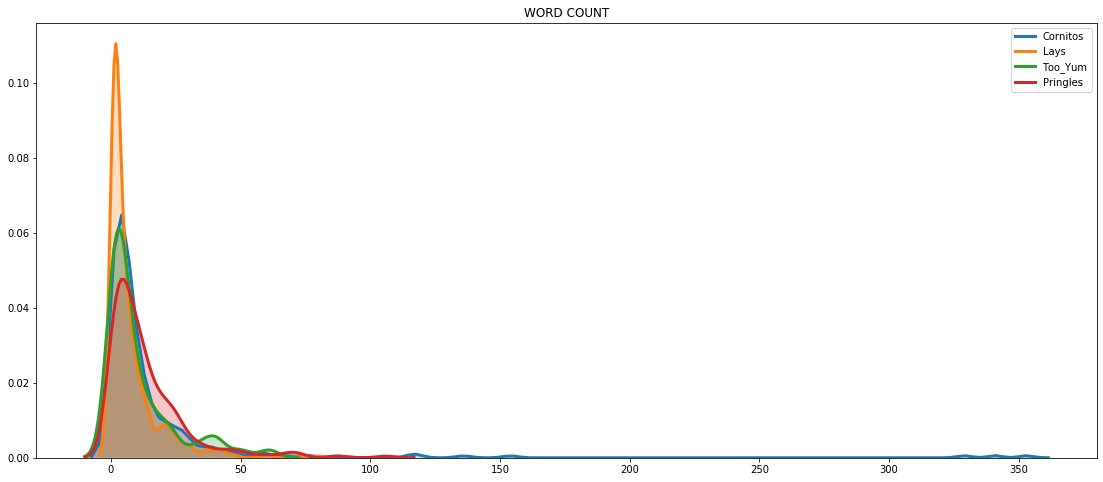

In [45]:
data= pd.DataFrame({'Word Count': df.word_count, 'label': df.Brand})
groups  = data.label.unique().tolist()
ins=list()
for group in groups:
    ins.append(data.loc[data.label== group]['Word Count'].tolist())
    
fig = plt.figure(figsize=(19,8))
ax = fig.add_subplot(1, 1, 1)

for inte, group in zip(ins, groups):
    sns.distplot(inte, hist = False, kde = True, kde_kws = {'shade': True, 'linewidth': 3}, label=group)

plt.title('WORD COUNT')
plt.legend(loc=1)
plt.show()

In [46]:
# Character Counts
df['char_count'] = df['reviews'].str.len() ## this also includes spaces
df[['reviews','char_count']].head()

,reviews,char_count
0,fresh and crunchy and none broken,33
1,Tastes amazing. But would have been good to ha...,324
2,All the individual chips were broken during tr...,179
3,"Features-1. You can sneak this to a multiplex,...",271
4,Its got that original taste of nachos.Really g...,138


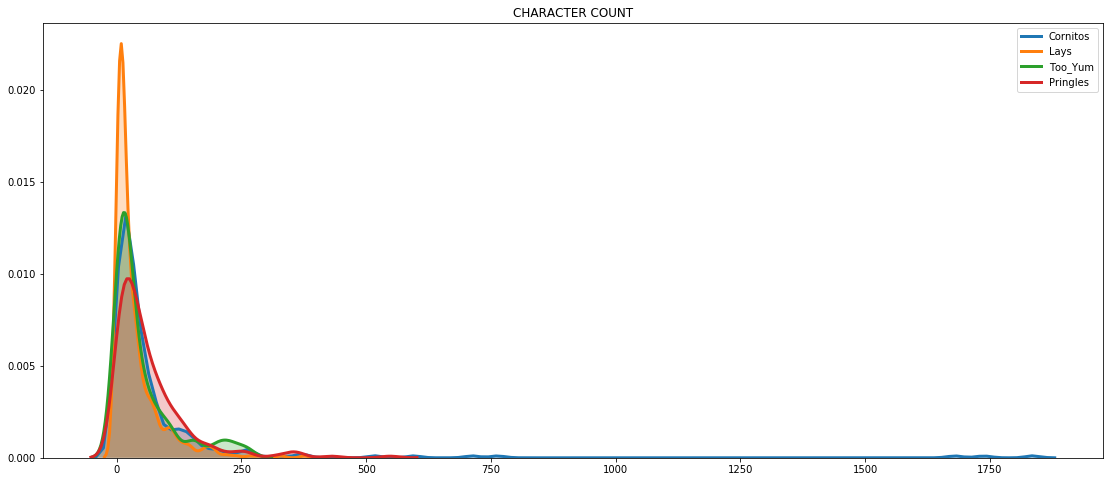

In [47]:
data= pd.DataFrame({'Chracter Count': df.char_count, 'label': df.Brand})
groups  = data.label.unique().tolist()
ins=list()
for group in groups:
    ins.append(data.loc[data.label== group]['Chracter Count'].tolist())
    
fig = plt.figure(figsize=(19,8))
ax = fig.add_subplot(1, 1, 1)

for inte, group in zip(ins, groups):
    sns.distplot(inte, hist = False, kde = True, kde_kws = {'shade': True, 'linewidth': 3}, label=group)

plt.title('CHARACTER COUNT')
plt.legend(loc=1)
plt.show()

In [48]:
# Average word length per sentence 
def avg_word(sentence):
    words = word_tokenize(sentence)
    return (sum(len(word) for word in words)/len(words))

df['avg_word'] = df['reviews'].apply(lambda x: avg_word(str(x)))
df[['reviews','avg_word']].head()

,reviews,avg_word
0,fresh and crunchy and none broken,4.666667
1,Tastes amazing. But would have been good to ha...,3.840580
2,All the individual chips were broken during tr...,3.769231
3,"Features-1. You can sneak this to a multiplex,...",3.590164
4,Its got that original taste of nachos.Really g...,4.958333


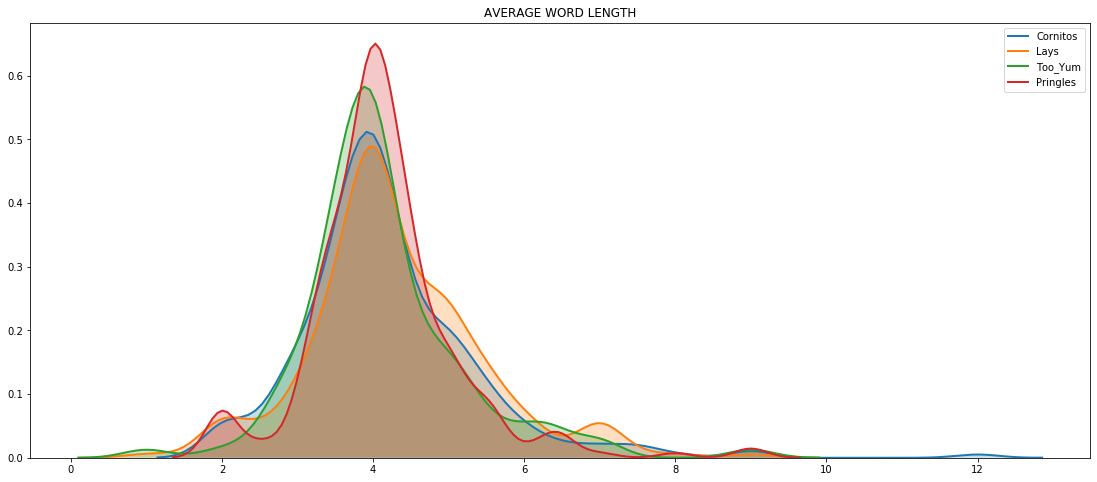

In [49]:
data= pd.DataFrame({'Average Word Count': df.avg_word, 'label': df.Brand})
groups  = data.label.unique().tolist()
ins=list()
for group in groups:
    ins.append(data.loc[data.label== group]['Average Word Count'].tolist())
    
fig = plt.figure(figsize=(19,8))
ax = fig.add_subplot(1, 1, 1)

for inte, group in zip(ins, groups):
    sns.distplot(inte, hist = False, kde = True, kde_kws = {'shade': True, 'linewidth': 2}, label=group)

plt.title('AVERAGE WORD LENGTH')
plt.legend(loc=1)
plt.show()

In [50]:
# Number of stopwords
from nltk.corpus import stopwords
stop = stopwords.words('english')
df['stopwords'] = df['reviews'].apply(lambda x: len([x for x in word_tokenize(x) if x in stop]))
df[['reviews','stopwords']].head()

,reviews,stopwords
0,fresh and crunchy and none broken,2
1,Tastes amazing. But would have been good to ha...,27
2,All the individual chips were broken during tr...,9
3,"Features-1. You can sneak this to a multiplex,...",29
4,Its got that original taste of nachos.Really g...,6


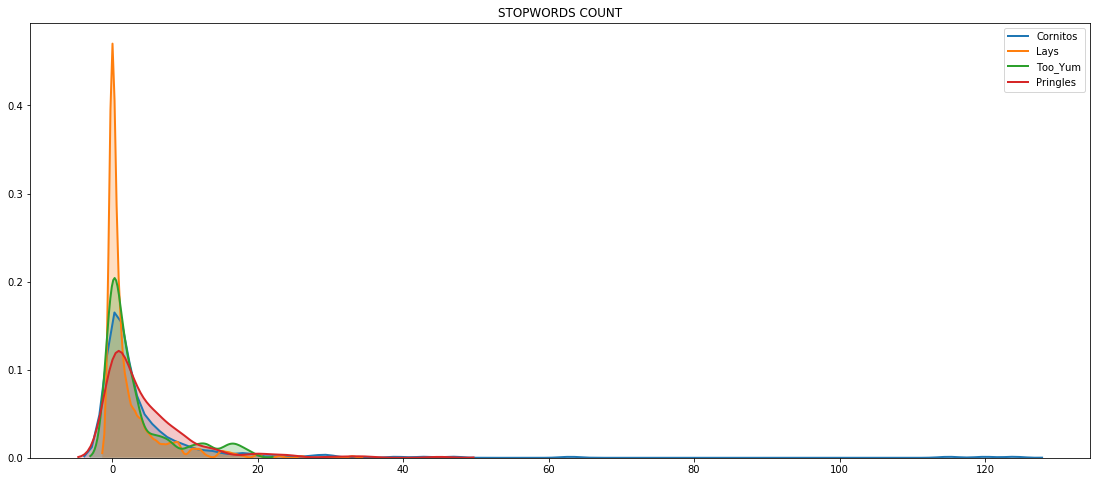

In [51]:
data= pd.DataFrame({'StopWords': df.stopwords, 'label': df.Brand})
groups  = data.label.unique().tolist()
ins=list()
for group in groups:
    ins.append(data.loc[data.label== group]['StopWords'].tolist())
    
fig = plt.figure(figsize=(19,8))
ax = fig.add_subplot(1, 1, 1)

for inte, group in zip(ins, groups):
    sns.distplot(inte, hist = False, kde = True, kde_kws = {'shade': True, 'linewidth': 2}, label=group)

plt.title('STOPWORDS COUNT')
plt.legend(loc=1)
plt.show()

In [52]:
# Number of punctuation
import string
df['special'] = df['reviews'].apply(lambda x: len([x for x in str(x) if x in string.punctuation]))
df[['reviews','special']].head()

,reviews,special
0,fresh and crunchy and none broken,0
1,Tastes amazing. But would have been good to ha...,10
2,All the individual chips were broken during tr...,6
3,"Features-1. You can sneak this to a multiplex,...",12
4,Its got that original taste of nachos.Really g...,6


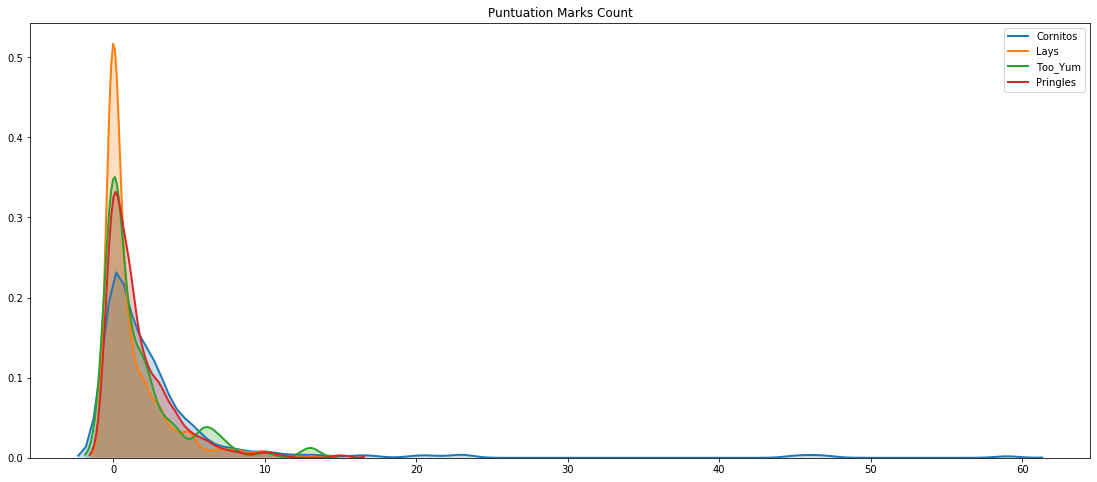

In [53]:
data= pd.DataFrame({'Special Character': df.special, 'label': df.Brand})
groups  = data.label.unique().tolist()
ins=list()
for group in groups:
    ins.append(data.loc[data.label== group]['Special Character'].tolist())
    
fig = plt.figure(figsize=(19,8))
ax = fig.add_subplot(1, 1, 1)

for inte, group in zip(ins, groups):
    sns.distplot(inte, hist = False, kde = True, kde_kws = {'shade': True, 'linewidth': 2}, label=group)

plt.title('Puntuation Marks Count')
plt.legend(loc=1)
plt.show()

### Text Processing

In [54]:
# Emoticons in Text
print("\U0001f600")
print("\U0001F606")
print("\U0001F923")

😀
😆
🤣


In [ ]:
# Counting Number of Emojis
df['count_emoticons']= ""
for i in range(df.shape[0]):
    cnt=0
    for j in range(len(df.reviews[i])):
        if df.reviews[i][j] in emoji.UNICODE_EMOJI:
            cnt= cnt+1
    df.count_emoticons[i]= cnt

In [57]:
print(emoji.demojize('😀'))
print(emoji.demojize('😆'))
print(emoji.demojize('🤣'))

:grinning_face:
:grinning_squinting_face:
:rolling_on_the_floor_laughing:


In [58]:
## Converting Emojis to Text
# Converting emoji to expressable text
import emoji
df['count_emoticons']= ""
for i in range(df.shape[0]):
    for j in range(len(df.reviews[i])):
        if df.reviews[i][j] in emoji.UNICODE_EMOJI:
            df.reviews[i]= str(df.reviews[i]).replace(df.reviews[i][j], emoji.demojize(df.reviews[i][j]).replace('_', " ").replace(':', ""))

C:\Users\manik\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


### Sentiment Analysis

In [60]:
df['sentiment_score'] = df.reviews.apply(lambda x: TextBlob(x).sentiment.polarity)

### Basic Text Processing

In [61]:
def clean_text(text):
    # lower text
    text = text.lower()

    # remove puncutation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # tokenize_text
    text = [word for word in word_tokenize(text)]
    
    # removing Stopwords
    text= [w for w in text if not w in stop] 

    # remove words that contain numbers
    text = [word for word in text if not any(c.isdigit() for c in word)]
    
    # remove empty tokens
    text = [t for t in text if len(t) > 0]

    # remove words with only one letter
    text = [t for t in text if len(t) > 1]

    # join all
    text = " ".join(text)
    return(text)

In [62]:
df['clean_reviews']= df.reviews.apply(clean_text)

In [63]:
df[['clean_reviews', 'reviews']].head(10)

,clean_reviews,reviews
0,fresh crunchy none broken,fresh and crunchy and none broken
1,tastes amazing would good sauce coming overall...,Tastes amazing. But would have been good to ha...
2,individual chips broken transit guess didnt ge...,All the individual chips were broken during tr...
3,sneak multiplex wont able tell nachos comfort ...,"Features-1. You can sneak this to a multiplex,..."
4,got original taste nachosreally good productfr...,Its got that original taste of nachos.Really g...
5,good product excellent taste issue less chips ...,"Good Product. Excellent taste. Only issue, les..."
6,grab lightning deal nachos big fav family add ...,had to grab it as it was on Lightning deal. Na...
7,perfect snack munch taste good bought amazon w...,A perfect snack to munch on. Taste was very go...
8,good alternative lays chitos lacks basic taste...,A good alternative to lays or chitos but it la...
9,favorite like taste best jalepeno taste right ...,These are my favorite. I like this taste the b...


In [64]:
df['rated'] = df.ratings.apply(lambda x: 'high_ratings' if x>=4 else 'low_ratings')

    Sometimes it's good to explore various options for visualizations for interactability or even just for a change. In that spirit, can you think of any other way to host a visualization?

    We can use a tableau widget with the help of html tags

In [65]:
%%html
<div class='tableauPlaceholder' id='viz1576562452143' style='position: relative'><noscript><a href='#'><img alt=' ' src='https:&#47;&#47;public.tableau.com&#47;static&#47;images&#47;So&#47;SocialMediaAnalysis_15683737236330&#47;Sheet2&#47;1_rss.png' style='border: none' /></a></noscript><object class='tableauViz'  style='display:none;'><param name='host_url' value='https%3A%2F%2Fpublic.tableau.com%2F' /> <param name='embed_code_version' value='3' /> <param name='site_root' value='' /><param name='name' value='SocialMediaAnalysis_15683737236330&#47;Sheet2' /><param name='tabs' value='no' /><param name='toolbar' value='yes' /><param name='static_image' value='https:&#47;&#47;public.tableau.com&#47;static&#47;images&#47;So&#47;SocialMediaAnalysis_15683737236330&#47;Sheet2&#47;1.png' /> <param name='animate_transition' value='yes' /><param name='display_static_image' value='yes' /><param name='display_spinner' value='yes' /><param name='display_overlay' value='yes' /><param name='display_count' value='yes' /></object></div>                <script type='text/javascript'>                    var divElement = document.getElementById('viz1576562452143');                    var vizElement = divElement.getElementsByTagName('object')[0];                    vizElement.style.width='100%';vizElement.style.height=(divElement.offsetWidth*0.75)+'px';                    var scriptElement = document.createElement('script');                    scriptElement.src = 'https://public.tableau.com/javascripts/api/viz_v1.js';                    vizElement.parentNode.insertBefore(scriptElement, vizElement);                </script>

In [66]:
df.to_csv('reviews.csv', index= False)

    What are uni, bi ,and trigrams? Why are they very commonly used in sentiment analysis?

    Like the names suggest they mean all running combinations of 1,2 or 3 words. Computers can't completely understand sentences directly hence we consider smaller chunks of words understand meaning of each and combining all chunks together to estimate the meaning of whole text

### Most Frequent Unigrams


*Steps:*

- Create four data frames separating each brand
- Join each and every reviews in each brand
- Now Tokenise and get the value counts
- Get the top 50 by values and append it to a Data frame

In [67]:
Cornitos = df.loc[df.Brand == 'Cornitos']
Lays = df.loc[df.Brand == 'Lays']
Too_Yum = df.loc[df.Brand == 'Too_Yum']
Pringles = df.loc[df.Brand == 'Pringles']

In [68]:
freq_Cornitos = pd.Series(' '.join(Cornitos['clean_reviews']).split()).value_counts()
freq_Lays = pd.Series(' '.join(Lays['clean_reviews']).split()).value_counts()
freq_Too_Yum = pd.Series(' '.join(Too_Yum['clean_reviews']).split()).value_counts()
freq_Pringles = pd.Series(' '.join(Pringles['clean_reviews']).split()).value_counts()

In [69]:
words_df= pd.DataFrame()

In [70]:
words_df= words_df.append(pd.DataFrame({"unigram": freq_Cornitos.index[:50], 
                              "uni_count": freq_Cornitos[:50], 
                              "Brand": ["Cornitos"]*50}), ignore_index= True)
words_df= words_df.append(pd.DataFrame({"unigram": freq_Lays.index[:50], 
                              "uni_count": freq_Lays[:50], 
                              "Brand": ["Lays"]*50}), ignore_index= True)
words_df= words_df.append(pd.DataFrame({"unigram": freq_Too_Yum.index[:50], 
                              "uni_count": freq_Too_Yum[:50], 
                              "Brand": ["Too Yum"]*50}), ignore_index= True)
words_df= words_df.append(pd.DataFrame({"unigram": freq_Pringles.index[:50], 
                              "uni_count": freq_Pringles[:50], 
                              "Brand": ["Pringles"]*50}), ignore_index= True)

In [71]:
words_df.head()

,unigram,uni_count,Brand
0,good,79,Cornitos
1,taste,56,Cornitos
2,product,41,Cornitos
3,nachos,40,Cornitos
4,chips,36,Cornitos


### Most Frequent Bigrams

*Steps:*

- Join each and every reviews in each brand
- Now Tokenise it
- Using nltk.bigrams get all possible bigrams.
- Get the top 50 by values and append it to a Data frame

In [72]:
def get_bigram(df):
    tokens = nltk.word_tokenize(' '.join(df['clean_reviews']))
    #Create your bigrams
    bgs = nltk.bigrams(tokens)
    key= []
    value= []
    fdist = nltk.FreqDist(bgs)
    for k,v in fdist.items():
        key.append(k)
        value.append(v)
    bi_df= pd.DataFrame({'Bigram': key, 'bi_count': value})
    bi_df= bi_df.sort_values(by= 'bi_count', ascending= False)
    bi_df= bi_df.reset_index(drop= True)
    def convertTuple(tup): 
        str =  ' '.join(tup) 
        return str
    bi_df.Bigram= bi_df.Bigram.apply(convertTuple)
    return bi_df

In [73]:
bigram_df= pd.DataFrame()
bigram_df= bigram_df.append(get_bigram(Cornitos).iloc[:50, :])
bigram_df= bigram_df.append(get_bigram(Lays).iloc[:50, :])
bigram_df= bigram_df.append(get_bigram(Too_Yum).iloc[:50, :])
bigram_df= bigram_df.append(get_bigram(Pringles).iloc[:50, :])
bigram_df.head()

,Bigram,bi_count
0,good product,12
1,nachos crisps,9
2,taste good,7
3,dont buy,6
4,tortilla chips,6


In [74]:
words_df.reset_index(drop= True, inplace= True)
bigram_df.reset_index(drop= True,  inplace= True)

In [75]:
words_df['bigram']= bigram_df['Bigram']
words_df['bi_count']= bigram_df['bi_count']

In [76]:
words_df.to_csv('words.csv', index= False)

### Filtering Based on Sentiment

Doing Analysis using only Negative Reviews, To know customers pain points

In [77]:
low_sentiment= df.loc[df.sentiment_score < 0]

In [78]:
low_sentiment.shape

(190, 13)

### Getting Most Frequent Negative Unigrams

Steps:

- Create four data frames separating each brand
- Join each and every reviews in each brand
- Now Tokenise and get the value counts
- Get the top 50 by values and append it to a Data frame

In [79]:
Cornitos = low_sentiment.loc[df.Brand == 'Cornitos']
Lays = low_sentiment.loc[df.Brand == 'Lays']
Too_Yum = low_sentiment.loc[df.Brand == 'Too_Yum']
Pringles = low_sentiment.loc[df.Brand == 'Pringles']

In [80]:
freq_Cornitos = pd.Series(' '.join(Cornitos['clean_reviews']).split()).value_counts()
freq_Lays = pd.Series(' '.join(Lays['clean_reviews']).split()).value_counts()
freq_Too_Yum = pd.Series(' '.join(Too_Yum['clean_reviews']).split()).value_counts()
freq_Pringles = pd.Series(' '.join(Pringles['clean_reviews']).split()).value_counts()

In [81]:
neg_words_df= pd.DataFrame()
neg_words_df= neg_words_df.append(pd.DataFrame({"unigram": freq_Cornitos.index[:50], 
                              "uni_count": freq_Cornitos[:50]}), ignore_index= True)
neg_words_df= neg_words_df.append(pd.DataFrame({"unigram": freq_Lays.index[:50], 
                              "uni_count": freq_Lays[:50]}), ignore_index= True)
neg_words_df= neg_words_df.append(pd.DataFrame({"unigram": freq_Too_Yum.index[:50], 
                              "uni_count": freq_Too_Yum[:50]}), ignore_index= True)
neg_words_df= neg_words_df.append(pd.DataFrame({"unigram": freq_Pringles.index[:50], 
                              "uni_count": freq_Pringles[:50]}), ignore_index= True)

In [82]:
neg_words_df.head()

,unigram,uni_count
0,taste,11
1,worst,10
2,like,10
3,buy,9
4,bad,8


### Most Frequent Bigrams in Negative Reviews

In [83]:
bigram_df= pd.DataFrame()
bigram_df= bigram_df.append(get_bigram(Cornitos).iloc[:50, :])
bigram_df= bigram_df.append(get_bigram(Lays).iloc[:50, :])
bigram_df= bigram_df.append(get_bigram(Too_Yum).iloc[:50, :])
bigram_df= bigram_df.append(get_bigram(Pringles).iloc[:50, :])
bigram_df.head()

,Bigram,bi_count
0,dont buy,5
1,worst taste,3
2,received product,2
3,one worst,2
4,crushed contents,2


### Most frequent Trigrams

*Steps:*

- Join each and every reviews in each brand
- Now Tokenise it
- Using nltk.Trigrams get all possible Trigrams.
- Get the top 50 by values and append it to a Data frame

In [84]:
def get_trigram(df):
    tokens = nltk.word_tokenize(' '.join(df['clean_reviews']))
    #Create your bigrams
    bgs = nltk.trigrams(tokens)
    key= []
    value= []
    fdist = nltk.FreqDist(bgs)
    for k,v in fdist.items():
        key.append(k)
        value.append(v)
    bi_df= pd.DataFrame({'Bigram': key, 'bi_count': value})
    bi_df= bi_df.sort_values(by= 'bi_count', ascending= False)
    bi_df= bi_df.reset_index(drop= True)
    def convertTuple(tup): 
        str =  ' '.join(tup) 
        return str
    bi_df.Bigram= bi_df.Bigram.apply(convertTuple)
    return bi_df

In [85]:
trigram_df= pd.DataFrame()
trigram_df= trigram_df.append(get_trigram(Cornitos).iloc[:50, :])
trigram_df= trigram_df.append(get_trigram(Lays).iloc[:50, :])
trigram_df= trigram_df.append(get_trigram(Too_Yum).iloc[:50, :])
trigram_df= trigram_df.append(get_trigram(Pringles).iloc[:50, :])
trigram_df.head()

,Bigram,bi_count
0,condition received product,2
1,worst taste worst,2
2,good condition received,2
3,product totally crushed,2
4,totally crushed contents,2


In [86]:
words_df['neg_uni']= neg_words_df.unigram
words_df['neg_uni_count']= neg_words_df.uni_count

In [87]:
bigram_df= bigram_df.reset_index(drop= True)

In [88]:
words_df['neg_bi']= bigram_df.Bigram
words_df['neg_bi_count']= bigram_df.bi_count

In [89]:
trigram_df= trigram_df.reset_index(drop= True)

In [90]:
words_df['neg_tri']= trigram_df.Bigram
words_df['neg_tri_count']= trigram_df.bi_count

In [91]:
words_df.head()

,unigram,uni_count,Brand,bigram,bi_count,neg_uni,neg_uni_count,neg_bi,neg_bi_count,neg_tri,neg_tri_count
0,good,79,Cornitos,good product,12,taste,11,dont buy,5,condition received product,2
1,taste,56,Cornitos,nachos crisps,9,worst,10,worst taste,3,worst taste worst,2
2,product,41,Cornitos,taste good,7,like,10,received product,2,good condition received,2
3,nachos,40,Cornitos,dont buy,6,buy,9,one worst,2,product totally crushed,2
4,chips,36,Cornitos,tortilla chips,6,bad,8,crushed contents,2,totally crushed contents,2


In [92]:
words_df.to_csv('words.csv', index= False)

### Getting all the Adjectives

*Steps:*

- Create a function get_adjective which takes in the data frame, iterates over each review finds out all the adjective and appends it to a series
- Do value counts on that series
- Segregate it for each brand 
- Get the top 50 adjectives for each brand

In [106]:
nlp = spacy.load('en_core_web_sm')

In [107]:
def get_adjective(df):
    adjectives_column= []
    for review in df.clean_reviews:
        doc= nlp(review)
        tokens= []
        for token in doc:
            if token.pos_ == 'ADJ':
                tokens.append(str(token))
        adjectives_column.append(" ".join(tokens))
    adj_freq = pd.Series(' '.join(adjectives_column).split()).value_counts()
    return adj_freq

In [108]:
get_adjective(Cornitos).shape[0]

37

In [109]:
adjective_df= pd.DataFrame()
adjective_df= adjective_df.append(pd.DataFrame({"adjective": get_adjective(Cornitos).index,
                                                 "Count": get_adjective(Cornitos),
                                                  "Brand": ['Cornitos'] * get_adjective(Cornitos).shape[0]}))
adjective_df= adjective_df.append(pd.DataFrame({"adjective": get_adjective(Lays).index,
                                                 "Count": get_adjective(Lays),
                                                  "Brand": ['Lays'] * get_adjective(Lays).shape[0]}))
adjective_df= adjective_df.append(pd.DataFrame({"adjective": get_adjective(Too_Yum).index,
                                                 "Count": get_adjective(Too_Yum),
                                                  "Brand": ['Too Yum'] * get_adjective(Too_Yum).shape[0]}))
adjective_df= adjective_df.append(pd.DataFrame({"adjective": get_adjective(Pringles).index,
                                                 "Count": get_adjective(Pringles),
                                                  "Brand": ['Pringles'] * get_adjective(Pringles).shape[0]}))

In [110]:
adjective_df= adjective_df.reset_index(drop= True)

In [111]:
adjective_df.to_csv('adjective.csv', index= False)

    As said earlier it is beneficial to try newer things while analyzing data and it is also time saving to create dashboard on tools like Tableau, one such dashboard for the above social media analytics is below

## Dashboard

In [112]:
%%html
<div class='tableauPlaceholder' id='viz1576564080859' style='position: relative'><noscript><a href='#'><img alt=' ' src='https:&#47;&#47;public.tableau.com&#47;static&#47;images&#47;So&#47;SocialMediaAnalysis_15683737236330&#47;Dashboard1&#47;1_rss.png' style='border: none' /></a></noscript><object class='tableauViz'  style='display:none;'><param name='host_url' value='https%3A%2F%2Fpublic.tableau.com%2F' /> <param name='embed_code_version' value='3' /> <param name='site_root' value='' /><param name='name' value='SocialMediaAnalysis_15683737236330&#47;Dashboard1' /><param name='tabs' value='no' /><param name='toolbar' value='yes' /><param name='static_image' value='https:&#47;&#47;public.tableau.com&#47;static&#47;images&#47;So&#47;SocialMediaAnalysis_15683737236330&#47;Dashboard1&#47;1.png' /> <param name='animate_transition' value='yes' /><param name='display_static_image' value='yes' /><param name='display_spinner' value='yes' /><param name='display_overlay' value='yes' /><param name='display_count' value='yes' /></object></div>                <script type='text/javascript'>                    var divElement = document.getElementById('viz1576564080859');                    var vizElement = divElement.getElementsByTagName('object')[0];                    vizElement.style.minWidth='1020px';vizElement.style.maxWidth='1220px';vizElement.style.width='100%';vizElement.style.height='3487px';                    var scriptElement = document.createElement('script');                    scriptElement.src = 'https://public.tableau.com/javascripts/api/viz_v1.js';                    vizElement.parentNode.insertBefore(scriptElement, vizElement);                </script>